# Multi-Dataset Protein Identification Analysis

This notebook analyzes protein identifications across multiple datasets with different experimental conditions. It identifies unique proteins shared across datasets and conditions to help understand shared, condition-specific, and dataset-specific protein distributions.

## Import Required Libraries

In [ ]:
import pandas as pd
import numpy as np
import os
from pathlib import Path
from collections import defaultdict
import warnings
warnings.filterwarnings('ignore')

# Visualization imports
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from matplotlib_venn import venn2, venn3

# Set visualization style
plt.style.use('seaborn-v0_8')
sns.set_palette("husl")

## Define Condition Mapping from 'Raw data location'

The 'Raw data location' column in your CSV files contains the experimental conditions. 
Edit the mapping below to extract the condition from this column based on identifiers in the file path.

In [10]:
# Create a mapping of identifiers in 'Raw data location' to condition names
# The function will search for these identifiers in the file path to extract the condition

condition_mapping = {
    # 'identifier_in_path': 'Condition Name',
    'MM1dEPproHSe': 'OS7mut1 culture filtrate',
    'MM1dEPos7HSe': 'OS7 culture filtrate',
    'MM1dEPHS': 'OS7 cells',
    '2020-08-16_I3_0_': 'Culture 0',
    '2020-08-16_I3_1_': 'Culture 1',
    '2020-08-16_I3_2_': 'Culture 2',
    '2020-08-16_I2_2_': 'Culture 2',
    '2020-08-16_I3_8_': 'Culture 8',
    'mm300Fe50S': 'High Iron Low Sulfur',
    'mm50Fe300S': 'Low Iron High Sulfur',
    'e1_f' : 'Fast Growth',
    'e1_m' : 'Medium Growth',
    'e1_s' : 'Slow Growth',
    'e2_f' : 'Fast Growth',
    'e2_m' : 'Medium Growth',
    'e2_s' : 'Slow Growth',
    'e5_f' : 'Fast Growth',
    'e5_m' : 'Medium Growth',
    'e5_s' : 'Slow Growth',
    'e5_e' : 'Experimental Growth?',
    'e5_xs' : 'Extra Slow Growth',
}

# Function to extract condition from Raw data location
def extract_condition_from_raw_location(raw_location, mapping):
    """
    Extract condition from the 'Raw data location' column based on the condition_mapping.
    
    Args:
        raw_location: The value from the 'Raw data location' column (usually a file path)
        mapping: The condition_mapping dictionary
    
    Returns:
        The condition name, or the original raw_location if no match found
    """
    if pd.isna(raw_location):
        return 'Unknown'
    
    raw_location_str = str(raw_location).lower()
    
    # Check if any key in the mapping appears in the raw_location
    for key, condition in mapping.items():
        if key.lower() in raw_location_str:
            return condition
    
    # If no match found, return the original location
    return raw_location

## Load and Merge Multiple CSV Files

Specify the directory containing your CSV files and load them into a unified DataFrame.

In [11]:
# Specify the directory containing your CSV files
csv_directory = r'c:\Users\Connor Lynch\Proteomics\project'  # Change this to your directory

# Load CSV files
def load_multiple_csvs(directory, condition_mapping):
    """
    Load multiple CSV files from a directory and extract condition from 'Raw data location'.
    
    Args:
        directory: Path to directory containing CSV files
        condition_mapping: Dictionary mapping identifiers to condition names
    
    Returns:
        A tuple of (merged_dataframe, dataset_info_dict)
    """
    csv_files = [f for f in os.listdir(directory) if f.endswith('.csv')]
    
    if not csv_files:
        print(f"No CSV files found in {directory}")
        return None, None
    
    dataframes = []
    dataset_info = {}
    
    for csv_file in csv_files:
        filepath = os.path.join(directory, csv_file)
        
        try:
            df = pd.read_csv(filepath)
            
            # Check if 'Raw data location' column exists
            if 'Raw data location' not in df.columns:
                print(f"Warning: '{csv_file}' does not have 'Raw data location' column. Skipping condition extraction.")
                condition_values = [csv_file] * len(df)
            else:
                # Extract conditions from 'Raw data location' column
                condition_values = df['Raw data location'].apply(lambda x: extract_condition_from_raw_location(x, condition_mapping))
            
            # Add dataset and condition columns
            df['Dataset'] = csv_file.replace('.csv', '')
            df['Condition'] = condition_values
            
            dataframes.append(df)
            dataset_info[csv_file] = {
                'num_rows': len(df),
                'unique_proteins': df['Protein ID'].nunique(),
                'unique_conditions': df['Condition'].nunique()
            }
            
            print(f"Loaded: {csv_file} | Unique Conditions: {dataset_info[csv_file]['unique_conditions']} | Proteins: {dataset_info[csv_file]['unique_proteins']}")
        
        except Exception as e:
            print(f"Error loading {csv_file}: {e}")
    
    if dataframes:
        merged_df = pd.concat(dataframes, ignore_index=True)
        return merged_df, dataset_info
    else:
        return None, None

# Load all CSV files
merged_df, dataset_info = load_multiple_csvs(csv_directory, condition_mapping)

if merged_df is not None:
    print(f"\nTotal rows in merged dataset: {len(merged_df)}")
    print(f"Total unique proteins across all datasets: {merged_df['Protein ID'].nunique()}")
    print(f"Total unique conditions across all datasets: {merged_df['Condition'].nunique()}")
    pd.set_option('display.max_columns', None)
    #print("\nFirst few rows of merged data:")
    #print(merged_df.head())
else:
    print("Failed to load CSV files. Please check the directory path.")

Loaded: MSV000086844_merged.csv | Unique Conditions: 5 | Proteins: 1131
Loaded: PXD010311_merged.csv | Unique Conditions: 3 | Proteins: 1004
Loaded: PXD047095_merged.csv | Unique Conditions: 4 | Proteins: 490
Loaded: PXD058718_merged.csv | Unique Conditions: 2 | Proteins: 946

Total rows in merged dataset: 553047
Total unique proteins across all datasets: 1333
Total unique conditions across all datasets: 14


## Save Merged Data for Use in Separate Visualization Notebook

The merged raw data is automatically saved to a CSV file so it can be easily loaded in a separate visualization notebook without re-running the data loading steps.


In [30]:
# Create output directory if it doesn't exist
output_dir = 'protein_analysis_results'
os.makedirs(output_dir, exist_ok=True)

# Save merged data immediately after loading
if merged_df is not None:
    merged_output_path = os.path.join(output_dir, 'merged_raw_data.csv')
    merged_df.to_csv(merged_output_path, index=False)
    print(f"Saved merged raw data to: {merged_output_path}")
    print(f"Shape: {merged_df.shape}")
    
    # Calculate and save protein statistics
    protein_stats = merged_df.groupby('Protein ID').agg({
        'Dataset': 'nunique',
        'Condition': 'nunique',
        'Protein ID': 'count'
    }).rename(columns={
        'Dataset': 'Num Datasets',
        'Condition': 'Num Conditions',
        'Protein ID': 'Total Identifications'
    })
    
    stats_output_path = os.path.join(output_dir, 'protein_statistics.csv')
    protein_stats.to_csv(stats_output_path)
    print(f"Saved protein statistics to: {stats_output_path}")
else:
    print("Cannot save data - merged_df is None")

Saved merged raw data to: protein_analysis_results\merged_raw_data.csv
Shape: (553047, 48)
Saved protein statistics to: protein_analysis_results\protein_statistics.csv


## Count Unique Proteins per Dataset

Calculate the number of unique proteins identified in each dataset file.

In [12]:
if merged_df is not None:
    # Count unique proteins per dataset
    proteins_per_dataset = merged_df.groupby('Dataset')['Protein ID'].nunique().reset_index()
    proteins_per_dataset.columns = ['Dataset', 'Unique Proteins']
    proteins_per_dataset = proteins_per_dataset.sort_values('Unique Proteins', ascending=False)
    
    print("Unique Proteins per Dataset:")
    print("=" * 50)
    print(proteins_per_dataset.to_string(index=False))
    print(f"\nTotal datasets: {len(proteins_per_dataset)}")
else:
    print("No data available. Please load CSV files first.")

Unique Proteins per Dataset:
            Dataset  Unique Proteins
MSV000086844_merged             1131
   PXD010311_merged             1004
   PXD058718_merged              946
   PXD047095_merged              490

Total datasets: 4


## Count Unique Proteins per Condition

Group the merged data by condition and count the number of unique proteins for each experimental condition.

In [13]:
if merged_df is not None:
    # Count unique proteins per condition
    proteins_per_condition = merged_df.groupby('Condition')['Protein ID'].nunique().reset_index()
    proteins_per_condition.columns = ['Condition', 'Unique Proteins']
    proteins_per_condition = proteins_per_condition.sort_values('Unique Proteins', ascending=False)
    
    print("Unique Proteins per Condition:")
    print("=" * 50)
    print(proteins_per_condition.to_string(index=False))
    print(f"\nTotal conditions: {len(proteins_per_condition)}")
else:
    print("No data available. Please load CSV files first.")

Unique Proteins per Condition:
               Condition  Unique Proteins
             Fast Growth              986
           Medium Growth              982
       Extra Slow Growth              971
               OS7 cells              939
             Slow Growth              930
    Low Iron High Sulfur              862
    High Iron Low Sulfur              804
OS7mut1 culture filtrate              668
    Experimental Growth?              631
    OS7 culture filtrate              531
               Culture 1              448
               Culture 0              399
               Culture 2              390
               Culture 8              372

Total conditions: 14


## Identify Proteins Unique to Single Dataset

Find proteins that appear in only one dataset file to identify dataset-specific protein identifications.

In [14]:
if merged_df is not None:
    # Count how many datasets each protein appears in
    protein_dataset_count = merged_df.groupby('Protein ID')['Dataset'].nunique().reset_index()
    protein_dataset_count.columns = ['Protein ID', 'Dataset Count']
    
    # Proteins found in only one dataset
    proteins_one_dataset = protein_dataset_count[protein_dataset_count['Dataset Count'] == 1]['Protein ID'].tolist()
    
    print(f"Proteins identified in only ONE dataset: {len(proteins_one_dataset)}")
    print("=" * 50)
    
    if proteins_one_dataset:
        # Show breakdown by dataset
        one_dataset_breakdown = merged_df[merged_df['Protein ID'].isin(proteins_one_dataset)].groupby('Dataset')['Protein ID'].nunique().reset_index()
        one_dataset_breakdown.columns = ['Dataset', 'Exclusive Proteins']
        one_dataset_breakdown = one_dataset_breakdown.sort_values('Exclusive Proteins', ascending=False)
        print("\nBreakdown of exclusive proteins per dataset:")
        print(one_dataset_breakdown.to_string(index=False))
        
        # Display some examples
        print(f"\nExample proteins unique to single dataset (first 10):")
        print(proteins_one_dataset[:10])
    else:
        print("No proteins found in only one dataset.")
else:
    print("No data available. Please load CSV files first.")

Proteins identified in only ONE dataset: 268

Breakdown of exclusive proteins per dataset:
            Dataset  Exclusive Proteins
MSV000086844_merged                 129
   PXD010311_merged                  80
   PXD058718_merged                  40
   PXD047095_merged                  19

Example proteins unique to single dataset (first 10):
['sp|F1SVN3|FDHA2_METMP F420-dependent formate dehydrogenase 2 subunit alpha OS=Methanococcus maripaludis (strain DSM 14266 / JCM 13030 / NBRC 101832 / S2 / LL) OX=267377 GN=fdhA2 PE=1 SV=1', 'sp|P0CW45|GLNB1_METMP Nitrogen fixation nifHD region glnB-like protein 1 OS=Methanococcus maripaludis (strain DSM 14266 / JCM 13030 / NBRC 101832 / S2 / LL) OX=267377 GN=glnBI PE=3 SV=1', 'sp|P60780|RNP2_METMP Ribonuclease P protein component 2 OS=Methanococcus maripaludis (strain DSM 14266 / JCM 13030 / NBRC 101832 / S2 / LL) OX=267377 GN=rnp2 PE=1 SV=1', 'sp|P60818|Y665_METMP UPF0305 protein MMP0665 OS=Methanococcus maripaludis (strain DSM 14266 / JCM 130

## Identify Proteins Unique to Single Condition

Find proteins that appear in only one experimental condition to identify condition-specific protein identifications.

In [15]:
if merged_df is not None:
    # Count how many conditions each protein appears in
    protein_condition_count = merged_df.groupby('Protein ID')['Condition'].nunique().reset_index()
    protein_condition_count.columns = ['Protein ID', 'Condition Count']
    
    # Proteins found in only one condition
    proteins_one_condition = protein_condition_count[protein_condition_count['Condition Count'] == 1]['Protein ID'].tolist()
    
    print(f"Proteins identified in only ONE condition: {len(proteins_one_condition)}")
    print("=" * 50)
    
    if proteins_one_condition:
        # Show breakdown by condition
        one_condition_breakdown = merged_df[merged_df['Protein ID'].isin(proteins_one_condition)].groupby('Condition')['Protein ID'].nunique().reset_index()
        one_condition_breakdown.columns = ['Condition', 'Exclusive Proteins']
        one_condition_breakdown = one_condition_breakdown.sort_values('Exclusive Proteins', ascending=False)
        print("\nBreakdown of exclusive proteins per condition:")
        print(one_condition_breakdown.to_string(index=False))
        
        # Display some examples
        print(f"\nExample proteins unique to single condition (first 10):")
        print(proteins_one_condition[:10])
    else:
        print("No proteins found in only one condition.")
else:
    print("No data available. Please load CSV files first.")

Proteins identified in only ONE condition: 144

Breakdown of exclusive proteins per condition:
               Condition  Exclusive Proteins
               OS7 cells                  58
    Low Iron High Sulfur                  19
             Fast Growth                  14
       Extra Slow Growth                  13
    High Iron Low Sulfur                  11
OS7mut1 culture filtrate                   6
           Medium Growth                   6
             Slow Growth                   5
               Culture 1                   4
               Culture 0                   3
               Culture 2                   2
    Experimental Growth?                   2
               Culture 8                   1

Example proteins unique to single condition (first 10):
['sp|F1SVN3|FDHA2_METMP F420-dependent formate dehydrogenase 2 subunit alpha OS=Methanococcus maripaludis (strain DSM 14266 / JCM 13030 / NBRC 101832 / S2 / LL) OX=267377 GN=fdhA2 PE=1 SV=1', 'sp|P0CW45|GLNB1_METMP Nit

## Generate Summary Report

Create and display a comprehensive summary report showing protein counts and uniqueness across datasets and conditions.

In [16]:
if merged_df is not None:
    print("\n" + "=" * 70)
    print("COMPREHENSIVE PROTEIN IDENTIFICATION SUMMARY REPORT")
    print("=" * 70)
    
    # Overall statistics
    print("\n1. OVERALL STATISTICS")
    print("-" * 70)
    total_proteins = merged_df['Protein ID'].nunique()
    total_peptides = merged_df['Sequence'].nunique() if 'Sequence' in merged_df.columns else 'N/A'
    total_identifications = len(merged_df)
    
    print(f"Total unique proteins across all datasets: {total_proteins}")
    print(f"Total unique peptides across all datasets: {total_peptides}")
    print(f"Total protein identifications (rows): {total_identifications}")
    
    # Proteins shared across datasets
    print("\n2. PROTEIN DISTRIBUTION ACROSS DATASETS")
    print("-" * 70)
    protein_dataset_dist = merged_df.groupby('Protein ID')['Dataset'].nunique().value_counts().sort_index(ascending=False)
    for num_datasets, count in protein_dataset_dist.items():
        print(f"Proteins in {num_datasets} dataset(s): {count}")
    
    # Proteins shared across conditions
    print("\n3. PROTEIN DISTRIBUTION ACROSS CONDITIONS")
    print("-" * 70)
    protein_condition_dist = merged_df.groupby('Protein ID')['Condition'].nunique().value_counts().sort_index(ascending=False)
    for num_conditions, count in protein_condition_dist.items():
        print(f"Proteins in {num_conditions} condition(s): {count}")
    
    # Summary by dataset
    print("\n4. SUMMARY BY DATASET")
    print("-" * 70)
    dataset_summary = merged_df.groupby('Dataset').agg({
        'Protein ID': 'nunique',
        'Sequence': 'nunique' if 'Sequence' in merged_df.columns else 'count'
    }).reset_index()
    dataset_summary.columns = ['Dataset', 'Unique Proteins', 'Unique Peptides' if 'Sequence' in merged_df.columns else 'Identifications']
    print(dataset_summary.to_string(index=False))
    
    # Summary by condition
    print("\n5. SUMMARY BY CONDITION")
    print("-" * 70)
    condition_summary = merged_df.groupby('Condition').agg({
        'Protein ID': 'nunique',
        'Sequence': 'nunique' if 'Sequence' in merged_df.columns else 'count'
    }).reset_index()
    condition_summary.columns = ['Condition', 'Unique Proteins', 'Unique Peptides' if 'Sequence' in merged_df.columns else 'Identifications']
    print(condition_summary.to_string(index=False))
    
    # Export results to CSV files (optional)
    print("\n6. EXPORTING RESULTS")
    print("-" * 70)
    output_dir = os.path.join(csv_directory, 'protein_analysis_results')
    os.makedirs(output_dir, exist_ok=True)
    
    # Export dataset summary
    dataset_summary.to_csv(os.path.join(output_dir, 'summary_by_dataset.csv'), index=False)
    print(f"✓ Exported: summary_by_dataset.csv")
    
    # Export condition summary
    condition_summary.to_csv(os.path.join(output_dir, 'summary_by_condition.csv'), index=False)
    print(f"✓ Exported: summary_by_condition.csv")
    
    # Export proteins unique to single dataset
    if proteins_one_dataset:
        single_dataset_df = merged_df[merged_df['Protein ID'].isin(proteins_one_dataset)][['Protein ID', 'Dataset', 'Condition']].drop_duplicates()
        single_dataset_df.to_csv(os.path.join(output_dir, 'proteins_single_dataset.csv'), index=False)
        print(f"✓ Exported: proteins_single_dataset.csv ({len(single_dataset_df)} unique proteins)")
    
    # Export proteins unique to single condition
    if proteins_one_condition:
        single_condition_df = merged_df[merged_df['Protein ID'].isin(proteins_one_condition)][['Protein ID', 'Dataset', 'Condition']].drop_duplicates()
        single_condition_df.to_csv(os.path.join(output_dir, 'proteins_single_condition.csv'), index=False)
        print(f"✓ Exported: proteins_single_condition.csv ({len(single_condition_df)} unique proteins)")
    
    # Export proteins in ALL conditions (one row per protein)
    num_conditions = merged_df['Condition'].nunique()
    protein_condition_count = merged_df.groupby('Protein ID')['Condition'].nunique()
    proteins_all_conditions = protein_condition_count[protein_condition_count == num_conditions].index.tolist()
    
    if proteins_all_conditions:
        filtered_df = merged_df[merged_df['Protein ID'].isin(proteins_all_conditions)]
        
        all_conditions_df = filtered_df.groupby('Protein ID').agg({
            'Dataset': 'nunique',
            'Sequence': 'nunique' if 'Sequence' in filtered_df.columns else 'first'
        }).reset_index()
        
        # Add total identifications count
        all_conditions_df['Total Identifications'] = filtered_df.groupby('Protein ID').size().values
        
        # Rename columns appropriately
        if 'Sequence' in filtered_df.columns:
            all_conditions_df = all_conditions_df[['Protein ID', 'Dataset', 'Sequence', 'Total Identifications']]
            all_conditions_df.columns = ['Protein ID', 'Num Datasets', 'Num Peptides', 'Total Identifications']
        else:
            all_conditions_df = all_conditions_df[['Protein ID', 'Dataset', 'Total Identifications']]
            all_conditions_df.columns = ['Protein ID', 'Num Datasets', 'Total Identifications']
        
        all_conditions_df.to_csv(os.path.join(output_dir, 'proteins_all_conditions.csv'), index=False)
        print(f"✓ Exported: proteins_all_conditions.csv ({len(proteins_all_conditions)} proteins)")

    print("\nAnalysis complete!")
else:
    print("No data available. Please load CSV files first.")


COMPREHENSIVE PROTEIN IDENTIFICATION SUMMARY REPORT

1. OVERALL STATISTICS
----------------------------------------------------------------------
Total unique proteins across all datasets: 1333
Total unique peptides across all datasets: 13047
Total protein identifications (rows): 553047

2. PROTEIN DISTRIBUTION ACROSS DATASETS
----------------------------------------------------------------------
Proteins in 4 dataset(s): 367
Proteins in 3 dataset(s): 439
Proteins in 2 dataset(s): 259
Proteins in 1 dataset(s): 268

3. PROTEIN DISTRIBUTION ACROSS CONDITIONS
----------------------------------------------------------------------
Proteins in 14 condition(s): 150
Proteins in 13 condition(s): 72
Proteins in 12 condition(s): 54
Proteins in 11 condition(s): 57
Proteins in 10 condition(s): 122
Proteins in 9 condition(s): 127
Proteins in 8 condition(s): 93
Proteins in 7 condition(s): 99
Proteins in 6 condition(s): 92
Proteins in 5 condition(s): 77
Proteins in 4 condition(s): 72
Proteins in 3 co

## Helper Functions and Tips

Use the functions below to perform additional analyses on your data.

In [17]:
def get_proteins_in_all_datasets(df):
    """Get proteins that appear in all datasets"""
    num_datasets = df['Dataset'].nunique()
    protein_counts = df.groupby('Protein ID')['Dataset'].nunique()
    return protein_counts[protein_counts == num_datasets].index.tolist()

def get_proteins_in_all_conditions(df):
    """Get proteins that appear in all conditions"""
    num_conditions = df['Condition'].nunique()
    protein_counts = df.groupby('Protein ID')['Condition'].nunique()
    return protein_counts[protein_counts == num_conditions].index.tolist()

def get_condition_specific_proteins(df, condition):
    """Get proteins specific to a particular condition"""
    condition_proteins = set(df[df['Condition'] == condition]['Protein ID'].unique())
    other_proteins = set(df[df['Condition'] != condition]['Protein ID'].unique())
    return list(condition_proteins - other_proteins)

def get_dataset_specific_proteins(df, dataset):
    """Get proteins specific to a particular dataset"""
    dataset_proteins = set(df[df['Dataset'] == dataset]['Protein ID'].unique())
    other_proteins = set(df[df['Dataset'] != dataset]['Protein ID'].unique())
    return list(dataset_proteins - other_proteins)

# =======================
# Example Usage
# =======================

if merged_df is not None:
    print("Example: Proteins appearing in all datasets and conditions")
    print("=" * 70)
    
    # Proteins in all datasets
    proteins_all_datasets = get_proteins_in_all_datasets(merged_df)
    print(f"\nProteins in ALL datasets: {len(proteins_all_datasets)}")
    if proteins_all_datasets:
        print(f"Examples: {proteins_all_datasets[:5]}")
    
    # Proteins in all conditions
    proteins_all_conditions = get_proteins_in_all_conditions(merged_df)
    print(f"\nProteins in ALL conditions: {len(proteins_all_conditions)}")
    if proteins_all_conditions:
        print(f"Examples: {proteins_all_conditions[:5]}")
    
    # Condition-specific example
    if len(merged_df['Condition'].unique()) > 0:
        first_condition = merged_df['Condition'].unique()[0]
        condition_specific = get_condition_specific_proteins(merged_df, first_condition)
        print(f"\nProteins ONLY in '{first_condition}': {len(condition_specific)}")
        if condition_specific:
            print(f"Examples: {condition_specific[:5]}")

Example: Proteins appearing in all datasets and conditions

Proteins in ALL datasets: 367
Examples: ['sp|O59648|GLNA_METMP Glutamine synthetase OS=Methanococcus maripaludis (strain DSM 14266 / JCM 13030 / NBRC 101832 / S2 / LL) OX=267377 GN=glnA PE=3 SV=1', 'sp|O74026|ARLY_METMP Argininosuccinate lyase OS=Methanococcus maripaludis (strain DSM 14266 / JCM 13030 / NBRC 101832 / S2 / LL) OX=267377 GN=argH PE=3 SV=2', 'sp|P0CW49|Y618_METMP Uncharacterized protein MMP0618 OS=Methanococcus maripaludis (strain DSM 14266 / JCM 13030 / NBRC 101832 / S2 / LL) OX=267377 GN=MMP0618 PE=4 SV=1', 'sp|P0CW59|RADA_METMP DNA repair and recombination protein RadA OS=Methanococcus maripaludis (strain DSM 14266 / JCM 13030 / NBRC 101832 / S2 / LL) OX=267377 GN=radA PE=3 SV=1', 'sp|P0CW63|METK_METMP S-adenosylmethionine synthase OS=Methanococcus maripaludis (strain DSM 14266 / JCM 13030 / NBRC 101832 / S2 / LL) OX=267377 GN=mat PE=3 SV=1']

Proteins in ALL conditions: 150
Examples: ['sp|O59648|GLNA_METMP Gl

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from matplotlib_venn import venn2, venn3
from upsetplot import plot as upset_plot
import numpy as np

# Set style
plt.style.use('seaborn-v0_8')
sns.set_palette("husl")

# Load the data
proteins_all = pd.read_csv('protein_analysis_results/proteins_all_conditions.csv')
proteins_single_dataset = pd.read_csv('protein_analysis_results/proteins_single_dataset.csv')
summary_dataset = pd.read_csv('protein_analysis_results/summary_by_dataset.csv')
summary_condition = pd.read_csv('protein_analysis_results/summary_by_condition.csv')

print("Data loaded successfully")
print(f"Total proteins across all conditions: {len(proteins_all)}")
print(f"Summary by dataset shape: {summary_dataset.shape}")
print(f"Summary by condition shape: {summary_condition.shape}")

Data loaded successfully
Total proteins across all conditions: 150
Summary by dataset shape: (4, 3)
Summary by condition shape: (14, 3)


# Visualizations

This section contains various visualizations for the proteomics analysis results.

### Using These Visualizations in a Separate Notebook

The following visualization cells are self-contained and can be run in a separate notebook. To do this:

1. Load the saved CSV files:
   - `merged_raw_data.csv` - Contains all raw data with Dataset and Condition columns
   - `protein_statistics.csv` - Contains pre-calculated protein statistics

2. Copy the import cell and the visualization cells to your new notebook
3. Replace the data loading with simple CSV reads (see example below)

Example data loading for separate notebook:
```python
merged_df = pd.read_csv('protein_analysis_results/merged_raw_data.csv')
protein_stats = pd.read_csv('protein_analysis_results/protein_statistics.csv', index_col='Protein ID')
```


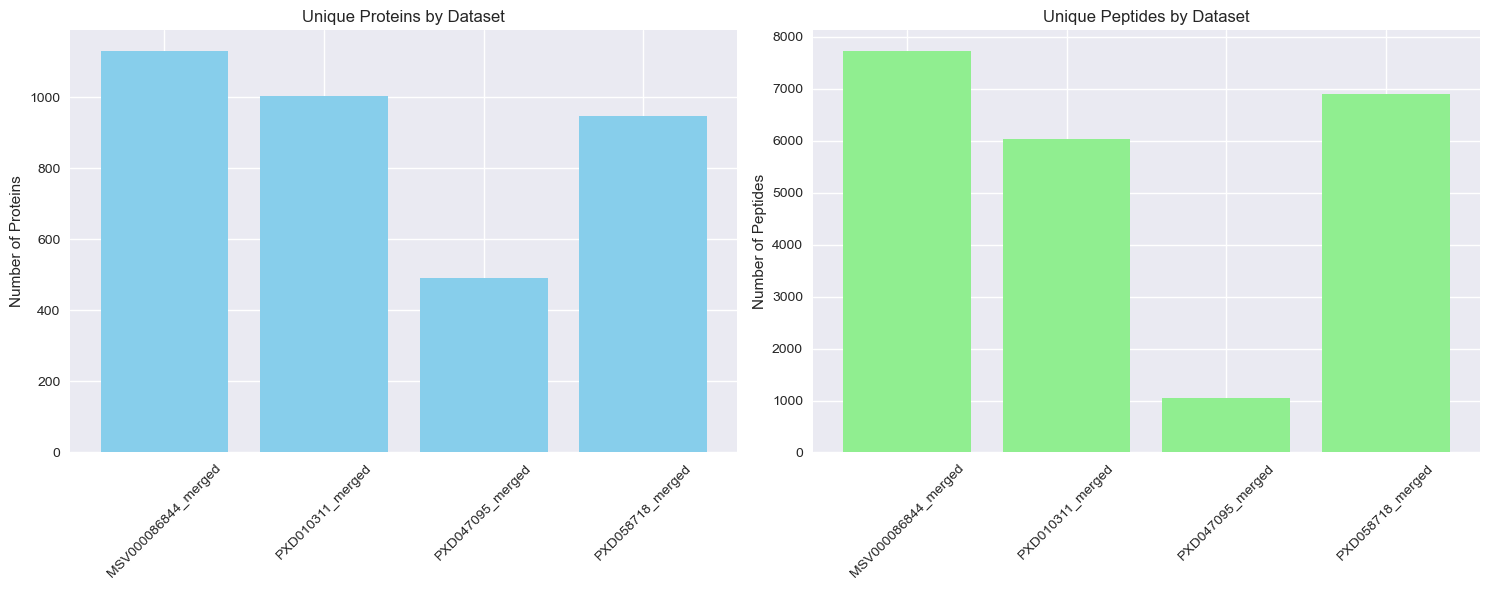

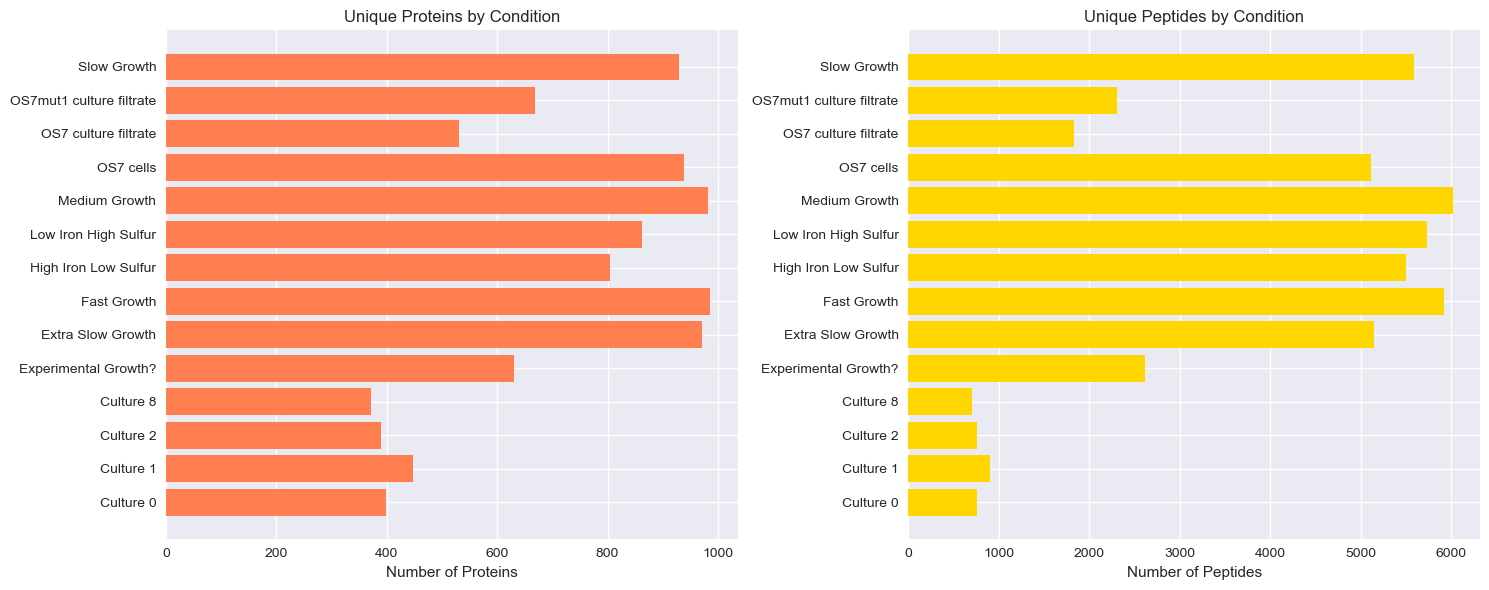

In [19]:
# Summary Statistics Visualizations

## Proteins and Peptides by Dataset
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Proteins by dataset
ax1.bar(summary_dataset['Dataset'], summary_dataset['Unique Proteins'], color='skyblue')
ax1.set_title('Unique Proteins by Dataset')
ax1.set_ylabel('Number of Proteins')
ax1.tick_params(axis='x', rotation=45)

# Peptides by dataset
ax2.bar(summary_dataset['Dataset'], summary_dataset['Unique Peptides'], color='lightgreen')
ax2.set_title('Unique Peptides by Dataset')
ax2.set_ylabel('Number of Peptides')
ax2.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

## Proteins and Peptides by Condition
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Proteins by condition
ax1.barh(summary_condition['Condition'], summary_condition['Unique Proteins'], color='coral')
ax1.set_title('Unique Proteins by Condition')
ax1.set_xlabel('Number of Proteins')

# Peptides by condition
ax2.barh(summary_condition['Condition'], summary_condition['Unique Peptides'], color='gold')
ax2.set_title('Unique Peptides by Condition')
ax2.set_xlabel('Number of Peptides')

plt.tight_layout()
plt.show()

Total unique proteins: 1333

Protein Statistics Summary:
       Num Datasets  Num Conditions  Total Identifications
count   1333.000000     1333.000000            1333.000000
mean       2.678920        7.436609             414.888972
std        1.082407        4.197265            1331.447148
min        1.000000        1.000000               1.000000
25%        2.000000        4.000000              12.000000
50%        3.000000        8.000000              84.000000
75%        4.000000       10.000000             355.000000
max        4.000000       14.000000           29944.000000


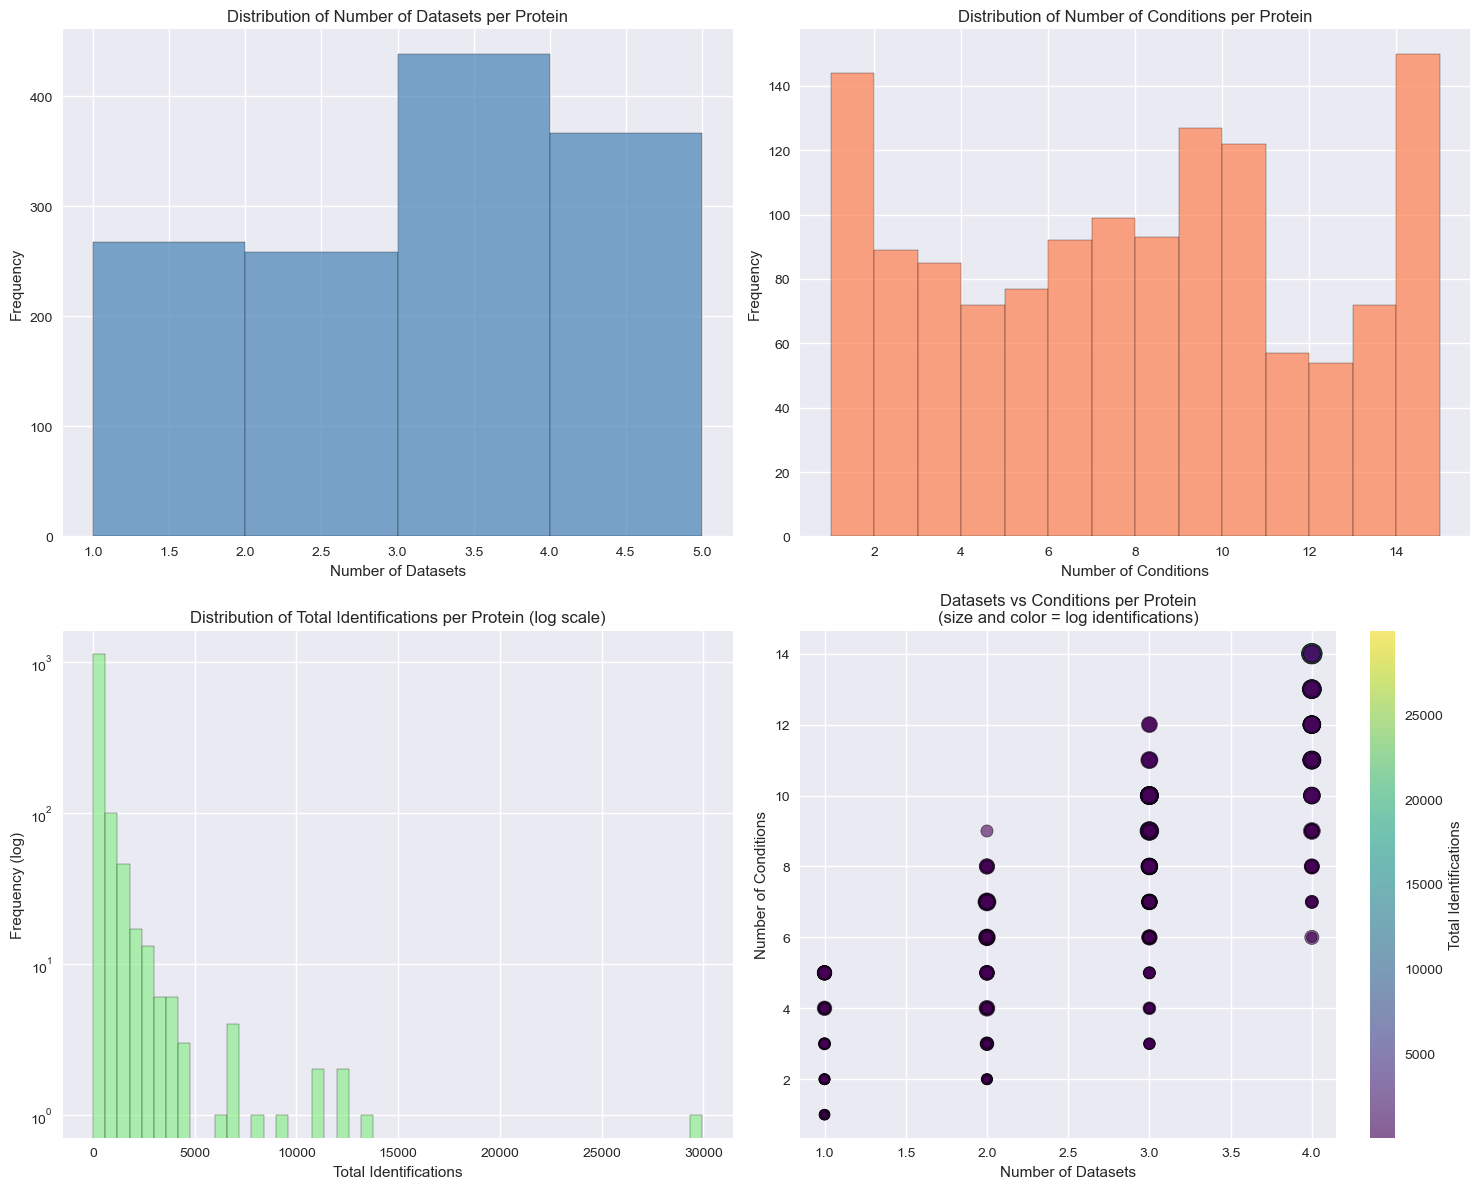

In [25]:
# Individual Protein Statistics from merged_df

# Calculate per-protein statistics from the raw merged data
protein_stats = merged_df.groupby('Protein ID').agg({
    'Dataset': 'nunique',  # Number of unique datasets
    'Condition': 'nunique',  # Number of unique conditions
    'Protein ID': 'count'   # Total occurrences (identifications)
}).rename(columns={
    'Dataset': 'Num Datasets',
    'Condition': 'Num Conditions',
    'Protein ID': 'Total Identifications'
})

print(f"Total unique proteins: {len(protein_stats)}")
print(f"\nProtein Statistics Summary:")
print(protein_stats.describe())

## Distribution of Protein Metrics
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(15, 12))

# Number of datasets per protein
ax1.hist(protein_stats['Num Datasets'], bins=range(1, int(protein_stats['Num Datasets'].max())+2), alpha=0.7, edgecolor='black', color='steelblue')
ax1.set_title('Distribution of Number of Datasets per Protein')
ax1.set_xlabel('Number of Datasets')
ax1.set_ylabel('Frequency')

# Number of conditions per protein
ax2.hist(protein_stats['Num Conditions'], bins=range(1, int(protein_stats['Num Conditions'].max())+2), alpha=0.7, edgecolor='black', color='coral')
ax2.set_title('Distribution of Number of Conditions per Protein')
ax2.set_xlabel('Number of Conditions')
ax2.set_ylabel('Frequency')

# Total identifications
ax3.hist(protein_stats['Total Identifications'], bins=50, alpha=0.7, edgecolor='black', log=True, color='lightgreen')
ax3.set_title('Distribution of Total Identifications per Protein (log scale)')
ax3.set_xlabel('Total Identifications')
ax3.set_ylabel('Frequency (log)')

# Scatter plot: Datasets vs Conditions, sized by Identifications
scatter = ax4.scatter(protein_stats['Num Datasets'], protein_stats['Num Conditions'], 
                     s=np.log10(protein_stats['Total Identifications']+1)*50, 
                     alpha=0.6, c=protein_stats['Total Identifications'], 
                     cmap='viridis', edgecolors='black', linewidth=0.5)
ax4.set_title('Datasets vs Conditions per Protein\n(size and color = log identifications)')
ax4.set_xlabel('Number of Datasets')
ax4.set_ylabel('Number of Conditions')
cbar = plt.colorbar(scatter, ax=ax4)
cbar.set_label('Total Identifications')

plt.tight_layout()
plt.show()

In [26]:
# Overlap Analysis Using All Unique Proteins from merged_df

## Dataset Protein Sets
dataset_proteins = {}
for dataset in merged_df['Dataset'].unique():
    dataset_proteins[dataset] = set(merged_df[merged_df['Dataset'] == dataset]['Protein ID'].unique())

print("All unique proteins per dataset (from merged_df):")
for ds, proteins in sorted(dataset_proteins.items()):
    print(f"{ds}: {len(proteins)} proteins")

## Condition Protein Sets
condition_proteins = {}
for condition in merged_df['Condition'].unique():
    condition_proteins[condition] = set(merged_df[merged_df['Condition'] == condition]['Protein ID'].unique())

print("\nAll unique proteins per condition (from merged_df):")
for cond, proteins in sorted(condition_proteins.items(), key=lambda x: len(x[1]), reverse=True):
    print(f"{cond}: {len(proteins)} proteins")

# Create sets for Venn diagram
datasets = list(dataset_proteins.keys())
sets = [dataset_proteins[ds] for ds in datasets]

print(f"\nDatasets: {datasets}")
print(f"Set sizes: {[len(s) for s in sets]}")

All unique proteins per dataset (from merged_df):
MSV000086844_merged: 1131 proteins
PXD010311_merged: 1004 proteins
PXD047095_merged: 490 proteins
PXD058718_merged: 946 proteins

All unique proteins per condition (from merged_df):
Fast Growth: 986 proteins
Medium Growth: 982 proteins
Extra Slow Growth: 971 proteins
OS7 cells: 939 proteins
Slow Growth: 930 proteins
Low Iron High Sulfur: 862 proteins
High Iron Low Sulfur: 804 proteins
OS7mut1 culture filtrate: 668 proteins
Experimental Growth?: 631 proteins
OS7 culture filtrate: 531 proteins
Culture 1: 448 proteins
Culture 0: 399 proteins
Culture 2: 390 proteins
Culture 8: 372 proteins

Datasets: ['MSV000086844_merged', 'PXD010311_merged', 'PXD047095_merged', 'PXD058718_merged']
Set sizes: [1131, 1004, 490, 946]


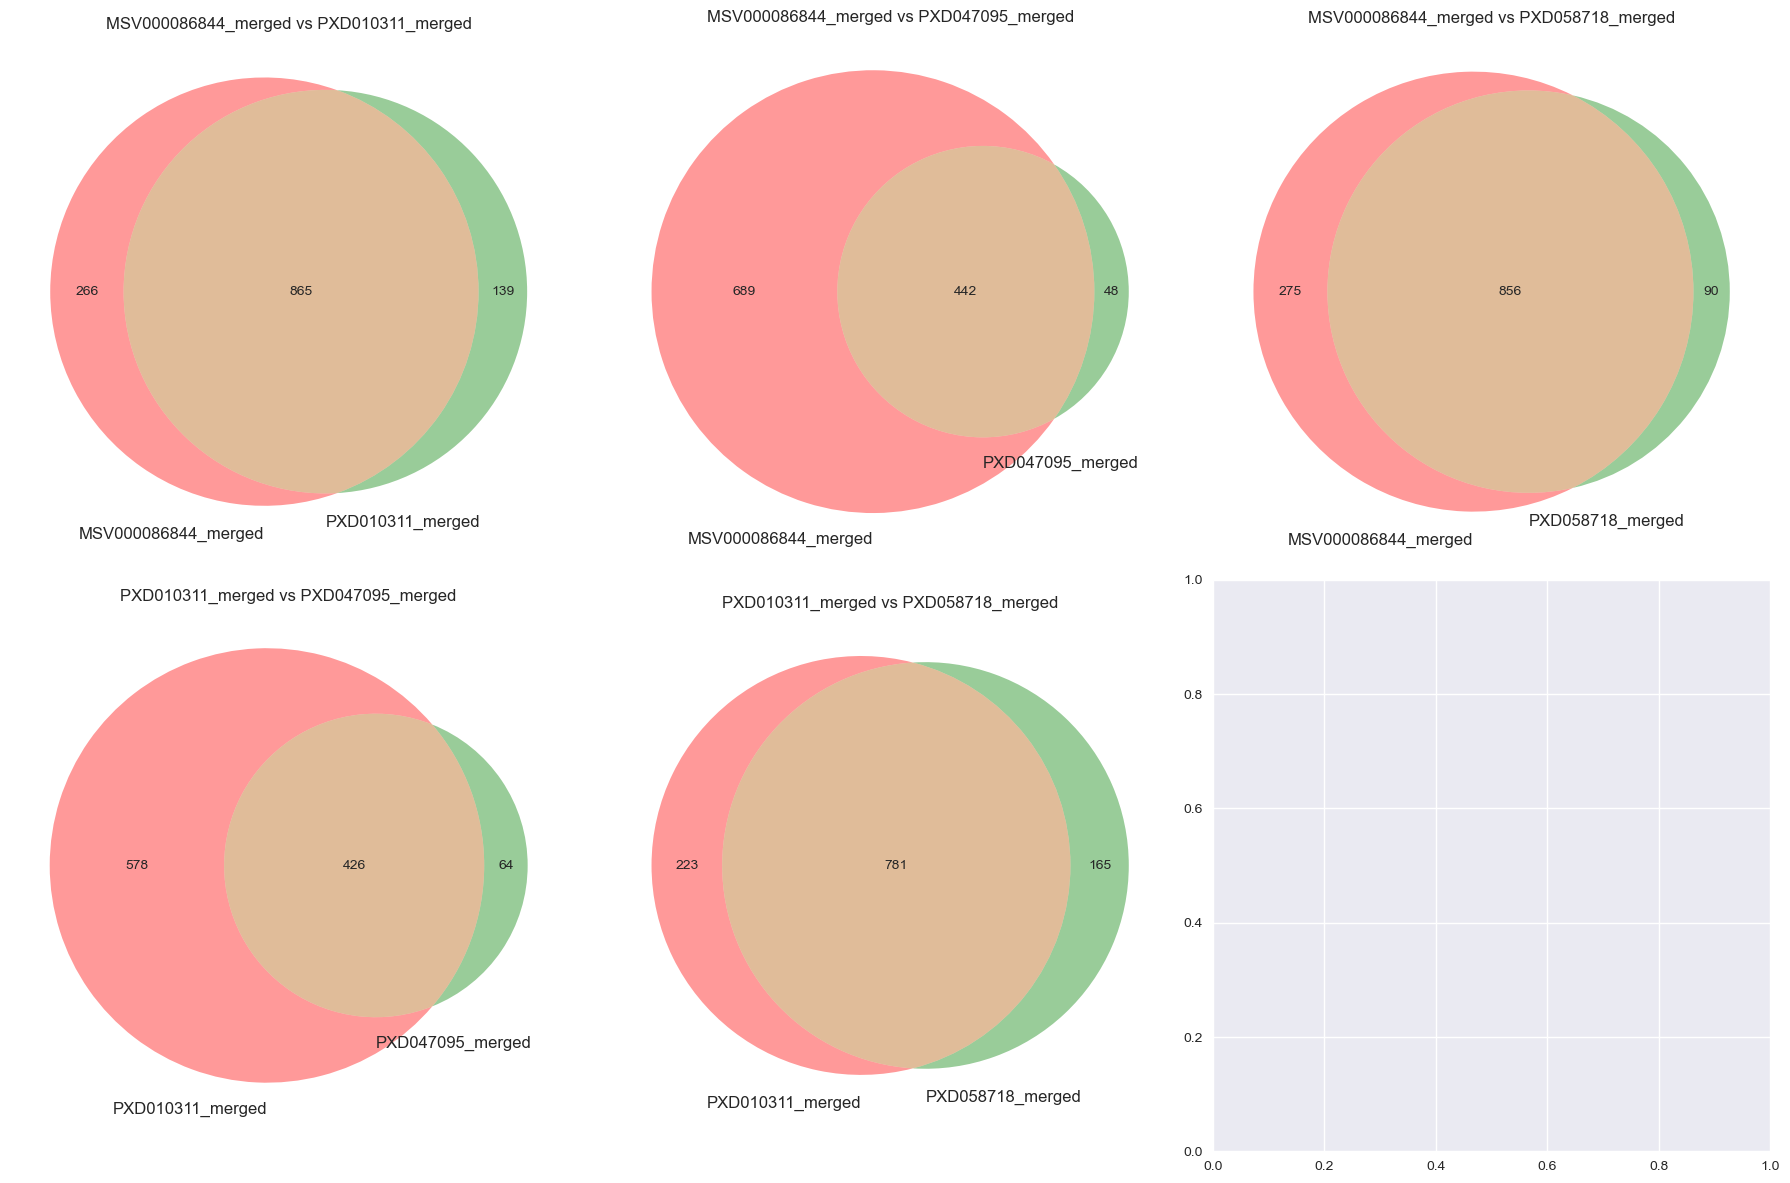

In [27]:
# Venn Diagram for Dataset Overlaps
# Since matplotlib-venn doesn't support 4 sets, we'll show pairwise comparisons
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

datasets = list(dataset_proteins.keys())
for i in range(len(datasets)):
    for j in range(i+1, len(datasets)):
        ax_idx = (i * (len(datasets)-1)) + (j - i - 1)
        if ax_idx < 6:  # Only 6 subplots
            venn2([dataset_proteins[datasets[i]], dataset_proteins[datasets[j]]],
                  set_labels=[datasets[i], datasets[j]], ax=axes[ax_idx])
            axes[ax_idx].set_title(f'{datasets[i]} vs {datasets[j]}')

# Hide unused subplots
for k in range(ax_idx + 1, 6):
    axes[k].set_visible(False)

plt.tight_layout()
plt.show()

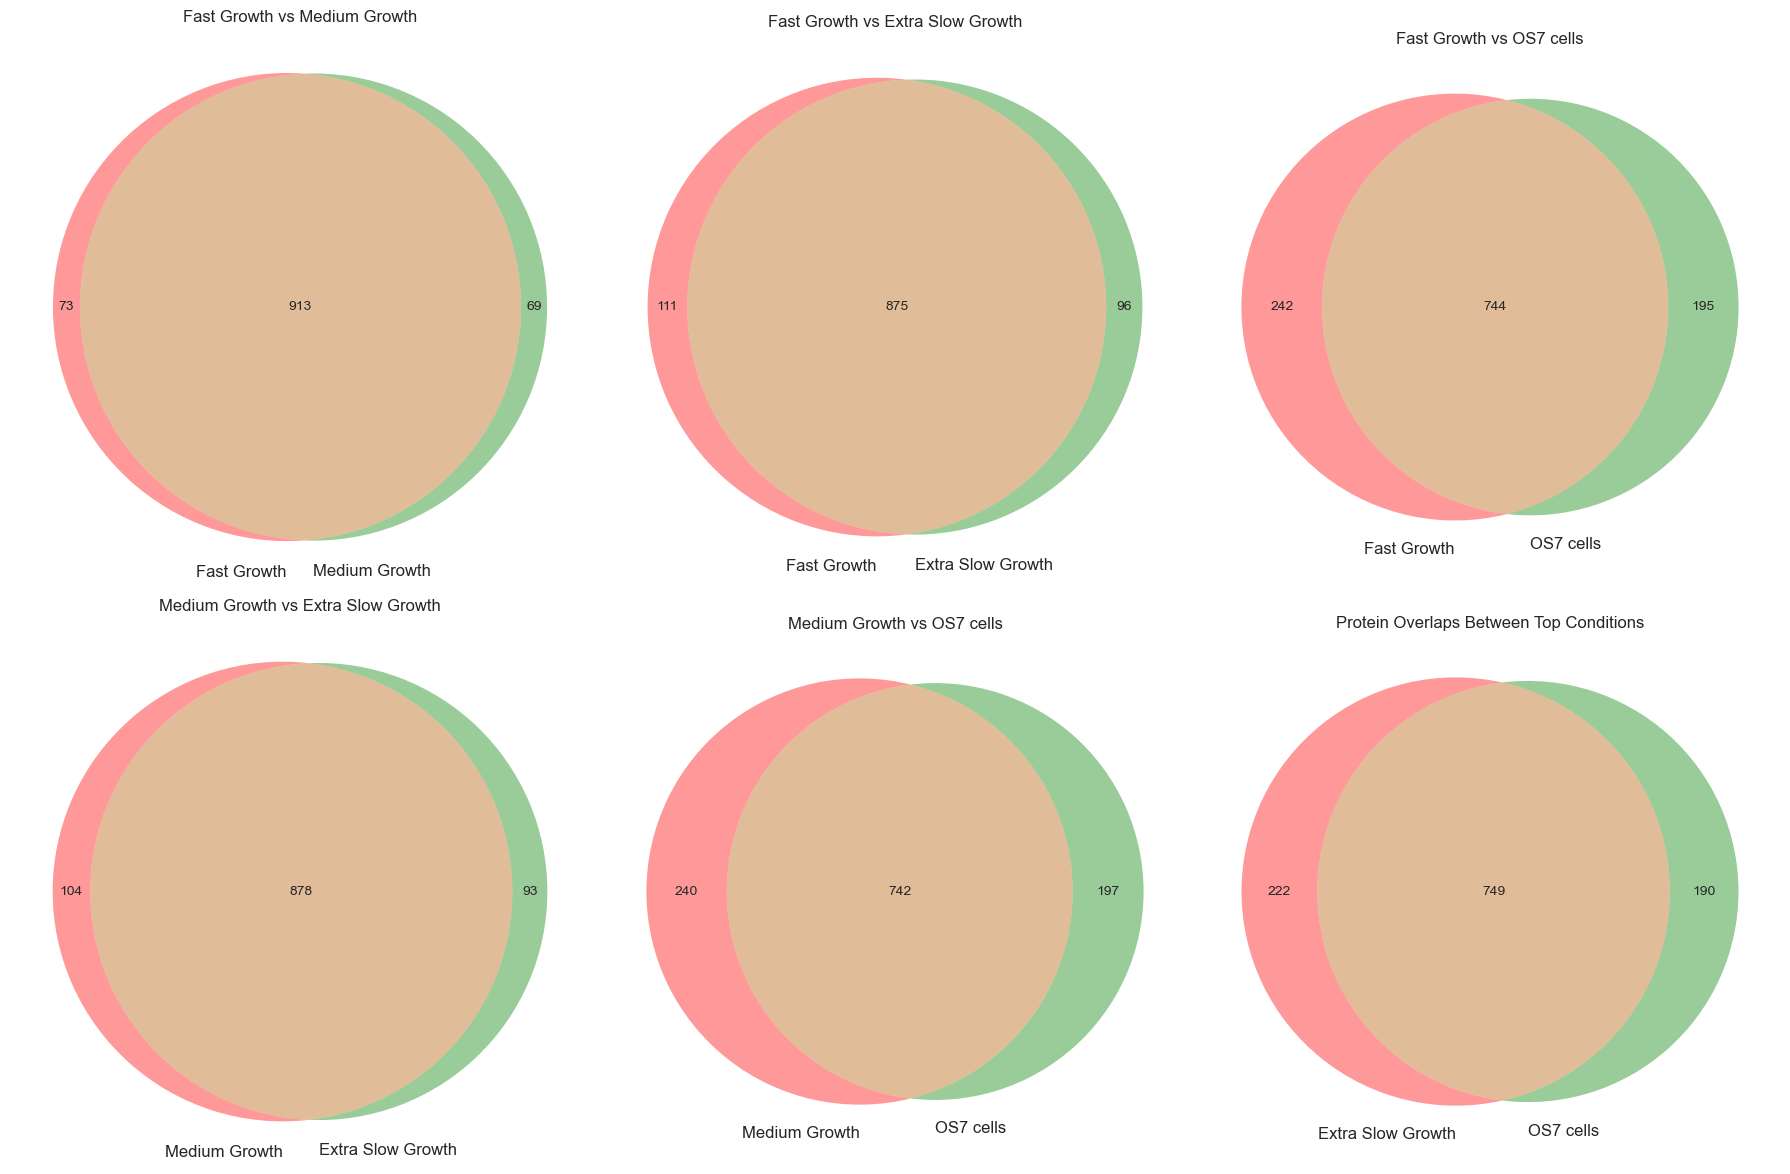

In [28]:
# Venn Diagram for Condition Overlaps
# Show pairwise comparisons for the top conditions by protein count

# Get top conditions by number of proteins
top_conditions = sorted(condition_proteins.items(), key=lambda x: len(x[1]), reverse=True)[:6]
top_condition_names = [c[0] for c in top_conditions]

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for idx, (i, j) in enumerate([(0,1), (0,2), (0,3), (1,2), (1,3), (2,3)]):
    if idx < len(axes) and i < len(top_condition_names) and j < len(top_condition_names):
        cond_i = top_condition_names[i]
        cond_j = top_condition_names[j]
        venn2([condition_proteins[cond_i], condition_proteins[cond_j]],
              set_labels=[cond_i, cond_j], ax=axes[idx])
        axes[idx].set_title(f'{cond_i} vs {cond_j}')

# Hide unused subplots
for k in range(idx + 1, 6):
    axes[k].set_visible(False)

plt.tight_layout()
plt.title('Protein Overlaps Between Top Conditions')
plt.show()

In [24]:
# Interactive Visualizations

## Scatter Plot: Proteins by Number of Peptides and Datasets
fig = px.scatter(proteins_all,
                 x='Num Peptides',
                 y='Total Identifications',
                 color='Num Datasets',
                 size='Num Datasets',
                 hover_name='Protein ID',
                 title='Protein Identifications: Peptides vs Total Identifications',
                 labels={'Num Peptides': 'Number of Peptides',
                        'Total Identifications': 'Total Identifications',
                        'Num Datasets': 'Number of Datasets'},
                 log_x=True,
                 log_y=True)

fig.update_layout(width=1000, height=600)
fig.show()

## Top Proteins by Identifications
top_proteins = proteins_all.nlargest(20, 'Total Identifications').copy()

# Extract protein names for better display
def extract_protein_name(protein_id):
    parts = str(protein_id).split()
    if len(parts) > 1:
        return ' '.join(parts[1:3])  # Take first two words after accession
    return str(protein_id)

top_proteins['Protein Name'] = top_proteins['Protein ID'].apply(extract_protein_name)

fig = px.bar(top_proteins,
             x='Total Identifications',
             y='Protein Name',
             orientation='h',
             title='Top 20 Proteins by Total Identifications',
             labels={'Total Identifications': 'Total Identifications',
                    'Protein Name': 'Protein'})

fig.update_layout(width=1000, height=800)
fig.show()

In [31]:
# Data has already been saved in the "Save Merged Data" section
# merged_raw_data.csv and protein_statistics.csv are available for use in separate notebooks

# Verify files exist
import os
output_files = [
    'protein_analysis_results/merged_raw_data.csv',
    'protein_analysis_results/protein_statistics.csv'
]

print("Data files saved for visualization notebook:")
for filepath in output_files:
    if os.path.exists(filepath):
        size = os.path.getsize(filepath) / (1024*1024)  # Size in MB
        print(f"✓ {filepath} ({size:.2f} MB)")
    else:
        print(f"✗ {filepath} (not found)")

Data files saved for visualization notebook:
✓ protein_analysis_results/merged_raw_data.csv (299.62 MB)
✓ protein_analysis_results/protein_statistics.csv (0.24 MB)
